In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    brier_score_loss
)

from sklearn.calibration import calibration_curve

In [2]:
df = pd.read_csv("heart.csv")

X = df.drop("HeartDisease", axis=1)
y = df["HeartDisease"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)
print("Testing:", X_test.shape)

Training: (642, 11)
Validation: (138, 11)
Testing: (138, 11)


In [3]:
num_cols = X.select_dtypes(include=np.number).columns.tolist()
cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_valid_processed = preprocessor.transform(X_valid)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("Preprocessing completed!")

Preprocessing completed!


In [4]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

model.fit(X_train_processed, y_train)

print("Model trained successfully!")

Model trained successfully!


Confusion Matrix:
[[51 10]
 [ 3 74]]

True Negative: 51
False Positive: 10
False Negative: 3
True Positive: 74


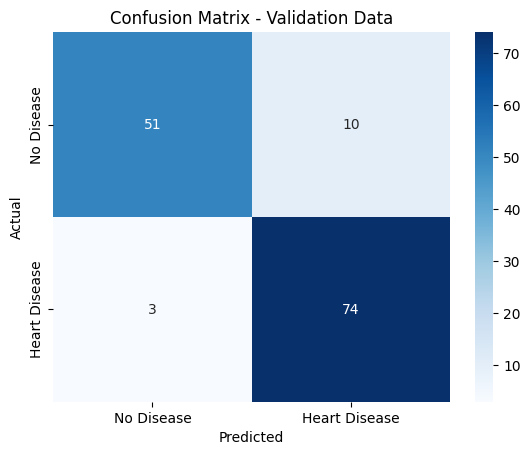

In [5]:
valid_prob = model.predict_proba(X_valid_processed)[:, 1]

# Default threshold
valid_pred = (valid_prob >= 0.50).astype(int)

cm = confusion_matrix(y_valid, valid_pred)

tn, fp, fn, tp = cm.ravel()

print("Confusion Matrix:")
print(cm)

print("\nTrue Negative:", tn)
print("False Positive:", fp)
print("False Negative:", fn)
print("True Positive:", tp)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Disease", "Heart Disease"],
    yticklabels=["No Disease", "Heart Disease"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Validation Data")
plt.show()

In [6]:
error_analysis = X_valid.copy()

error_analysis["Actual"] = y_valid.values
error_analysis["Predicted"] = valid_pred
error_analysis["Disease_Probability"] = valid_prob

error_analysis["Error_Type"] = np.where(
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1),
    "False Positive",
    np.where(
        (error_analysis["Actual"] == 1) &
        (error_analysis["Predicted"] == 0),
        "False Negative",
        "Correct"
    )
)

false_positives = error_analysis[
    error_analysis["Error_Type"] == "False Positive"
]

false_negatives = error_analysis[
    error_analysis["Error_Type"] == "False Negative"
]

print("False Positive Examples:")
display(false_positives.head(10))

print("False Negative Examples:")
display(false_negatives.head(10))

False Positive Examples:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Actual,Predicted,Disease_Probability,Error_Type
314,53,M,ASY,80,0,0,Normal,141,Y,2.0,Down,0,1,0.86,False Positive
844,52,M,TA,118,186,0,LVH,190,N,0.0,Flat,0,1,0.56,False Positive
310,65,M,ASY,155,0,0,Normal,154,N,1.0,Up,0,1,0.61,False Positive
840,41,M,ATA,135,203,0,Normal,132,N,0.0,Flat,0,1,0.69,False Positive
566,41,M,ASY,150,171,0,Normal,128,Y,1.5,Flat,0,1,0.99,False Positive
455,59,M,ASY,154,0,0,ST,131,Y,1.5,Up,0,1,0.67,False Positive
600,57,M,ASY,130,207,0,ST,96,Y,1.0,Flat,0,1,0.92,False Positive
434,63,M,ASY,126,0,0,ST,120,N,1.5,Down,0,1,0.82,False Positive
252,61,M,ASY,125,292,0,ST,115,Y,0.0,Up,0,1,0.60,False Positive
636,48,M,ATA,130,245,0,LVH,180,N,0.2,Flat,0,1,0.50,False Positive


False Negative Examples:


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,Actual,Predicted,Disease_Probability,Error_Type
873,64,M,NAP,140,335,0,Normal,158,N,0.0,Up,1,0,0.08,False Negative
643,58,M,NAP,112,230,0,LVH,165,N,2.5,Flat,1,0,0.41,False Negative
102,40,F,ASY,150,392,0,Normal,130,N,2.0,Flat,1,0,0.49,False Negative


In [7]:
numeric_features = X_valid.select_dtypes(
    include=np.number
).columns.tolist()

fp_mean = false_positives[numeric_features].mean()
fn_mean = false_negatives[numeric_features].mean()

pattern_comparison = pd.DataFrame({
    "False_Positive_Mean": fp_mean,
    "False_Negative_Mean": fn_mean
})

pattern_comparison["Difference"] = (
    pattern_comparison["False_Positive_Mean"] -
    pattern_comparison["False_Negative_Mean"]
)

print(pattern_comparison)

             False_Positive_Mean  False_Negative_Mean  Difference
Age                        54.00                 54.0        0.00
RestingBP                 130.30                134.0       -3.70
Cholesterol               130.40                319.0     -188.60
FastingBS                   0.00                  0.0        0.00
MaxHR                     138.70                151.0      -12.30
Oldpeak                     0.87                  1.5       -0.63


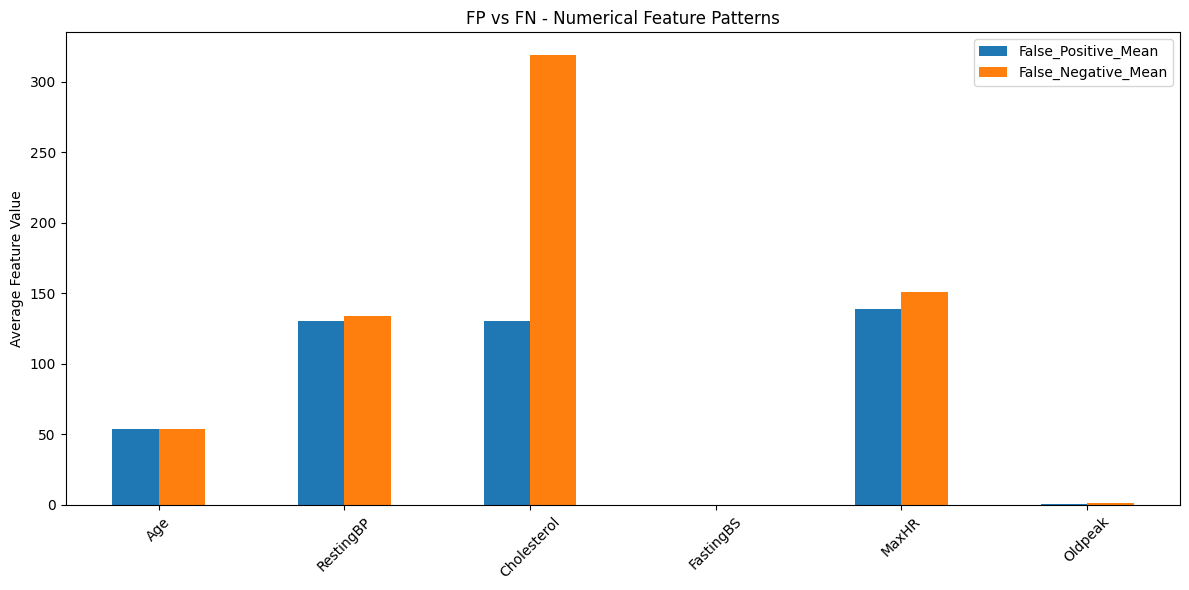

In [8]:
if len(pattern_comparison) > 0:
    pattern_comparison[
        ["False_Positive_Mean", "False_Negative_Mean"]
    ].plot(
        kind="bar",
        figsize=(12, 6)
    )

    plt.title("FP vs FN - Numerical Feature Patterns")
    plt.ylabel("Average Feature Value")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

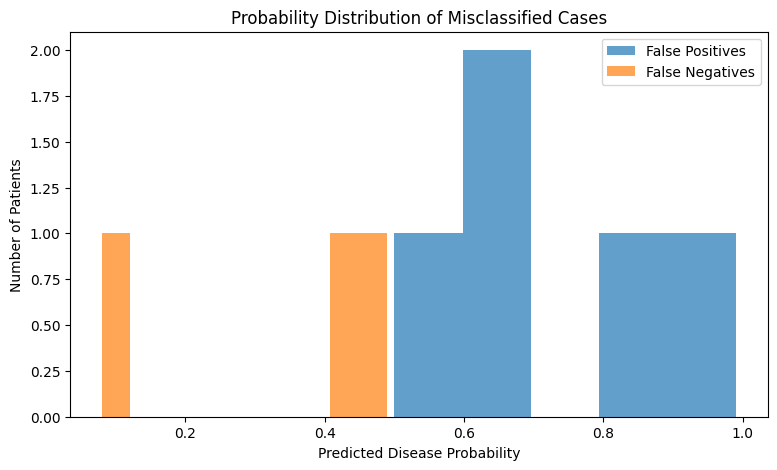

In [9]:
plt.figure(figsize=(9, 5))

plt.hist(
    false_positives["Disease_Probability"],
    bins=10,
    alpha=0.7,
    label="False Positives"
)

plt.hist(
    false_negatives["Disease_Probability"],
    bins=10,
    alpha=0.7,
    label="False Negatives"
)

plt.xlabel("Predicted Disease Probability")
plt.ylabel("Number of Patients")
plt.title("Probability Distribution of Misclassified Cases")
plt.legend()
plt.show()

In [10]:
for col in cat_cols:

    print("\nFeature:", col)

    print("\nFalse Positive Distribution:")
    print(
        false_positives[col].value_counts(normalize=True)
    )

    print("\nFalse Negative Distribution:")
    print(
        false_negatives[col].value_counts(normalize=True)
    )


Feature: Sex

False Positive Distribution:
Sex
M    1.0
Name: proportion, dtype: float64

False Negative Distribution:
Sex
M    0.666667
F    0.333333
Name: proportion, dtype: float64

Feature: ChestPainType

False Positive Distribution:
ChestPainType
ASY    0.7
ATA    0.2
TA     0.1
Name: proportion, dtype: float64

False Negative Distribution:
ChestPainType
NAP    0.666667
ASY    0.333333
Name: proportion, dtype: float64

Feature: RestingECG

False Positive Distribution:
RestingECG
Normal    0.4
ST        0.4
LVH       0.2
Name: proportion, dtype: float64

False Negative Distribution:
RestingECG
Normal    0.666667
LVH       0.333333
Name: proportion, dtype: float64

Feature: ExerciseAngina

False Positive Distribution:
ExerciseAngina
Y    0.5
N    0.5
Name: proportion, dtype: float64

False Negative Distribution:
ExerciseAngina
N    1.0
Name: proportion, dtype: float64

Feature: ST_Slope

False Positive Distribution:
ST_Slope
Flat    0.5
Up      0.3
Down    0.2
Name: proportion, dty

In [11]:
from sklearn.metrics import fbeta_score

threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    predictions = (
        valid_prob >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_valid,
        predictions,
        labels=[0, 1]
    ).ravel()

    precision = precision_score(
        y_valid, predictions, zero_division=0
    )

    recall = recall_score(
        y_valid, predictions, zero_division=0
    )

    f2 = fbeta_score(
        y_valid, predictions,
        beta=2,
        zero_division=0
    )

    threshold_results.append({
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Precision": precision,
        "Recall": recall,
        "F2_Score": f2
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df.round(3).to_string(index=False))

 Threshold  FP  FN  Precision  Recall  F2_Score
      0.10  36   1      0.679   0.987     0.905
      0.15  26   1      0.745   0.987     0.927
      0.20  21   1      0.784   0.987     0.938
      0.25  19   1      0.800   0.987     0.943
      0.30  15   1      0.835   0.987     0.952
      0.35  13   1      0.854   0.987     0.957
      0.40  12   1      0.864   0.987     0.960
      0.45  12   2      0.862   0.974     0.949
      0.50   9   3      0.892   0.961     0.946
      0.55   9   5      0.889   0.935     0.925
      0.60   7   8      0.908   0.896     0.898
      0.65   6   9      0.919   0.883     0.890
      0.70   4  15      0.939   0.805     0.829
      0.75   4  18      0.937   0.766     0.795
      0.80   4  27      0.926   0.649     0.691
      0.85   3  38      0.929   0.506     0.557
      0.90   2  45      0.941   0.416     0.468


In [12]:
best_row = threshold_df.loc[
    threshold_df["F2_Score"].idxmax()
]

best_threshold = best_row["Threshold"]

print("Best Threshold:", best_threshold)
print("Best Validation F2:", best_row["F2_Score"])
print("Validation FP:", best_row["FP"])
print("Validation FN:", best_row["FN"])

Best Threshold: 0.40000000000000013
Best Validation F2: 0.9595959595959596
Validation FP: 12.0
Validation FN: 1.0


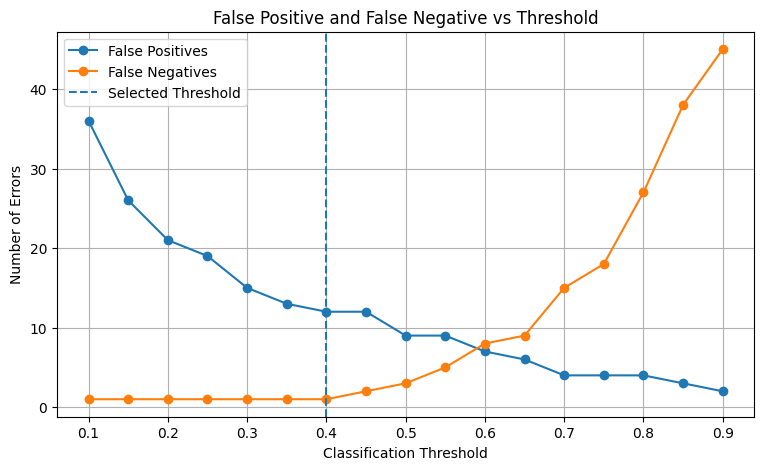

In [13]:
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FP"],
    marker="o",
    label="False Positives"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["FN"],
    marker="o",
    label="False Negatives"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Selected Threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Number of Errors")
plt.title("False Positive and False Negative vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
from sklearn.calibration import CalibratedClassifierCV

calibrated_model = CalibratedClassifierCV(
    estimator=RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ),
    method="sigmoid",
    cv=5
)

calibrated_model.fit(
    X_train_processed,
    y_train
)

calibrated_valid_prob = calibrated_model.predict_proba(
    X_valid_processed
)[:, 1]

print("Calibration completed!")

Calibration completed!


In [15]:
calibrated_threshold_results = []

for threshold in np.arange(0.10, 0.91, 0.05):

    pred = (
        calibrated_valid_prob >= threshold
    ).astype(int)

    calibrated_threshold_results.append({
        "Threshold": threshold,
        "F2_Score": fbeta_score(
            y_valid, pred,
            beta=2,
            zero_division=0
        ),
        "FP": confusion_matrix(
            y_valid, pred, labels=[0, 1]
        )[0, 1],
        "FN": confusion_matrix(
            y_valid, pred, labels=[0, 1]
        )[1, 0]
    })

calibrated_threshold_df = pd.DataFrame(
    calibrated_threshold_results
)

calibrated_best_row = calibrated_threshold_df.loc[
    calibrated_threshold_df["F2_Score"].idxmax()
]

calibrated_best_threshold = calibrated_best_row["Threshold"]

print("Calibrated Best Threshold:", calibrated_best_threshold)
print(calibrated_best_row)

Calibrated Best Threshold: 0.30000000000000004
Threshold     0.300000
F2_Score      0.952381
FP           15.000000
FN            1.000000
Name: 4, dtype: float64


Original Brier Score: 0.08242898550724638
Calibrated Brier Score: 0.08164229414547142


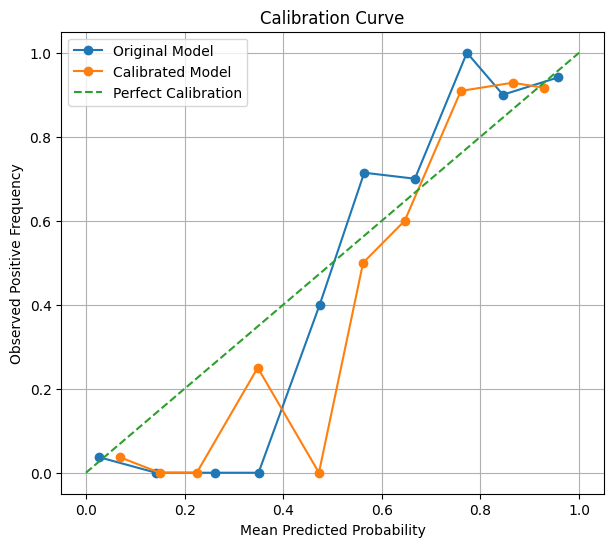

In [16]:
baseline_brier = brier_score_loss(
    y_valid,
    valid_prob
)

calibrated_brier = brier_score_loss(
    y_valid,
    calibrated_valid_prob
)

print("Original Brier Score:", baseline_brier)
print("Calibrated Brier Score:", calibrated_brier)

fraction_original, mean_original = calibration_curve(
    y_valid,
    valid_prob,
    n_bins=10,
    strategy="uniform"
)

fraction_calibrated, mean_calibrated = calibration_curve(
    y_valid,
    calibrated_valid_prob,
    n_bins=10,
    strategy="uniform"
)

plt.figure(figsize=(7, 6))

plt.plot(
    mean_original,
    fraction_original,
    marker="o",
    label="Original Model"
)

plt.plot(
    mean_calibrated,
    fraction_calibrated,
    marker="o",
    label="Calibrated Model"
)

plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Perfect Calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Observed Positive Frequency")
plt.title("Calibration Curve")
plt.legend()
plt.grid(True)
plt.show()

In [17]:
test_prob_original = model.predict_proba(
    X_test_processed
)[:, 1]

test_prob_calibrated = calibrated_model.predict_proba(
    X_test_processed
)[:, 1]

original_test_pred = (
    test_prob_original >= 0.50
).astype(int)

adjusted_test_pred = (
    test_prob_calibrated >= calibrated_best_threshold
).astype(int)

In [18]:
def calculate_metrics(actual, predicted, probabilities):

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(
            actual, predicted, zero_division=0
        ),
        "Recall": recall_score(
            actual, predicted, zero_division=0
        ),
        "F1": f1_score(
            actual, predicted, zero_division=0
        ),
        "F2": fbeta_score(
            actual, predicted, beta=2, zero_division=0
        ),
        "Specificity": tn / (tn + fp) if tn + fp else 0,
        "FP": fp,
        "FN": fn,
        "Brier_Score": brier_score_loss(actual, probabilities)
    }


before = calculate_metrics(
    y_test, original_test_pred, test_prob_original
)

after = calculate_metrics(
    y_test, adjusted_test_pred, test_prob_calibrated
)

final_comparison = pd.DataFrame(
    [before, after],
    index=["Original Model (0.50)", "Calibrated + Adjusted"]
)

print(final_comparison.round(4))

                       Accuracy  Precision  Recall      F1      F2  \
Original Model (0.50)    0.8913     0.9296  0.8684  0.8980  0.8800   
Calibrated + Adjusted    0.8478     0.8235  0.9211  0.8696  0.8997   

                       Specificity  FP  FN  Brier_Score  
Original Model (0.50)       0.9194   5  10       0.0876  
Calibrated + Adjusted       0.7581  15   6       0.0853  


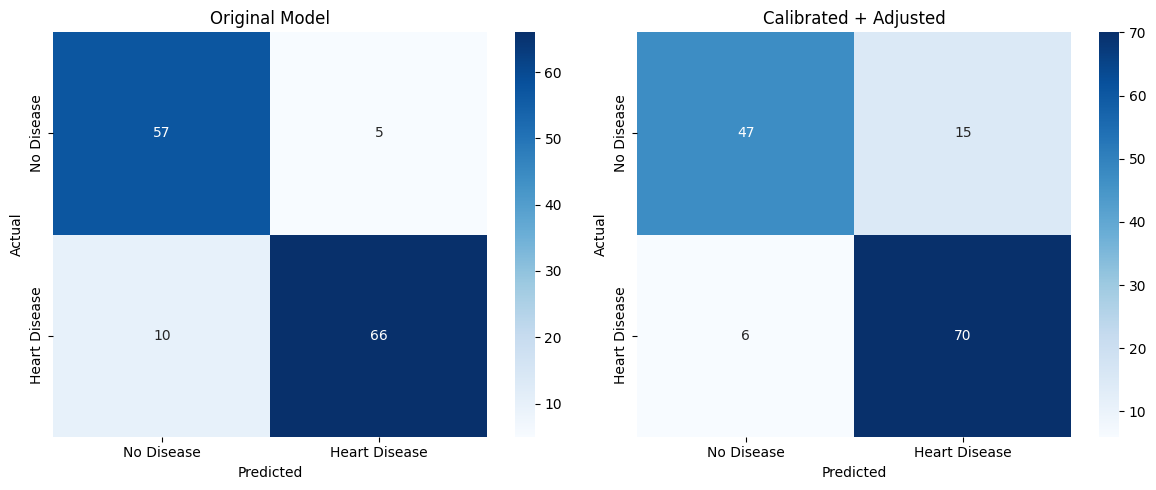

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, predictions, title in zip(
    axes,
    [original_test_pred, adjusted_test_pred],
    ["Original Model", "Calibrated + Adjusted"]
):

    cm = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Disease", "Heart Disease"],
        yticklabels=["No Disease", "Heart Disease"],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()